<a href="https://colab.research.google.com/github/DarshChoudhary-09/Gig-Optimization-Analysis/blob/main/GigEarningOptimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving gigs_clean.csv to gigs_clean.csv
Saving gigs_skills.csv to gigs_skills.csv
Saving time_tracking_clean.csv to time_tracking_clean.csv
Saving transaction_clean.csv to transaction_clean.csv
Saving workers_data_clean.csv to workers_data_clean.csv


In [ ]:
from pathlib import Path

DATA = Path("/content")

OUT = Path("/content/outputs")
OUT.mkdir(exist_ok=True)

print("Data folder:", DATA)
print("Output folder:", OUT)

Data folder: /content
Output folder: /content/outputs


In [ ]:

import pandas as pd
from pathlib import Path


DATA = Path("/content")


OUT = Path("/content/outputs")
OUT.mkdir(exist_ok=True)


workers  = pd.read_csv(DATA / "workers_data_clean.csv")
tx       = pd.read_csv(DATA / "transaction_clean.csv")
gigs     = pd.read_csv(DATA / "gigs_clean.csv", parse_dates=["posted_at"])
g_skills = pd.read_csv(DATA / "gigs_skills.csv")
tt       = pd.read_csv(DATA / "time_tracking_clean.csv")


tables = {
    "workers": workers,
    "transactions": tx,
    "gigs": gigs,
    "gig_skills": g_skills,
    "time_tracking": tt
}


report = pd.DataFrame({
    "rows": {
        n: len(d) for n, d in tables.items()
    },
    "columns": {
        n: d.shape[1] for n, d in tables.items()
    },
    "null_cells": {
        n: int(d.isna().sum().sum()) for n, d in tables.items()
    },
    "duplicate_rows": {
        n: int(d.duplicated().sum()) for n, d in tables.items()
    },
})

display(report)


,rows,columns,null_cells,duplicate_rows
workers,500,12,0,0
transactions,1950,23,0,0
gigs,52977,17,177814,0
gig_skills,263240,2,0,0
time_tracking,10000,22,0,0


In [ ]:
# Experience level mapping
experience_mapping = {
    "junior": 1,
    "mid": 2,
    "senior": 3,
    "expert": 4
}

workers["experience_order"] = (
    workers["experience_level"]
    .str.lower()
    .str.strip()
    .map(experience_mapping)
)

# Education mapping
education_mapping = {
    "high school": 1,
    "associate": 2,
    "bachelor": 3,
    "master": 4,
    "phd": 5
}

workers["education_order"] = (
    workers["education"]
    .str.lower()
    .str.strip()
    .map(education_mapping)
)

In [ ]:
print(workers[[
    "experience_level",
    "experience_order",
    "education",
    "education_order"
]].head(10))

  experience_level  experience_order    education  education_order
0           junior                 1       Master              4.0
1           senior                 3     Bootcamp              NaN
2              mid                 2  Self-taught              NaN
3              mid                 2  Self-taught              NaN
4           senior                 3  Self-taught              NaN
5           senior                 3  Self-taught              NaN
6              mid                 2       Master              4.0
7              mid                 2     Bachelor              3.0
8              mid                 2  Self-taught              NaN
9           senior                 3     Bachelor              3.0


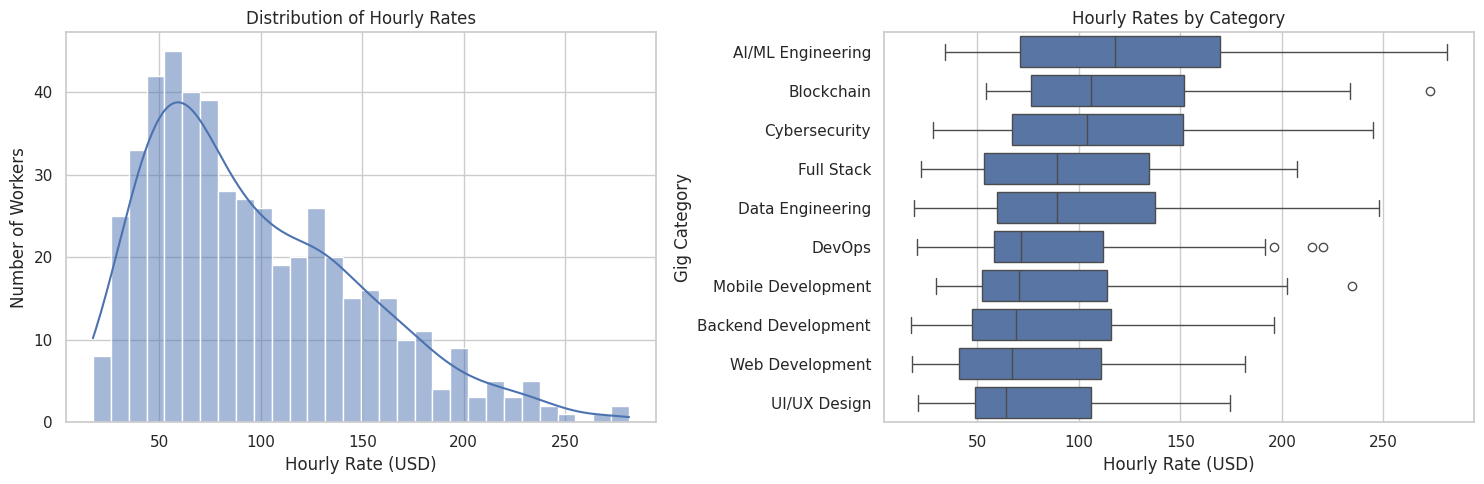

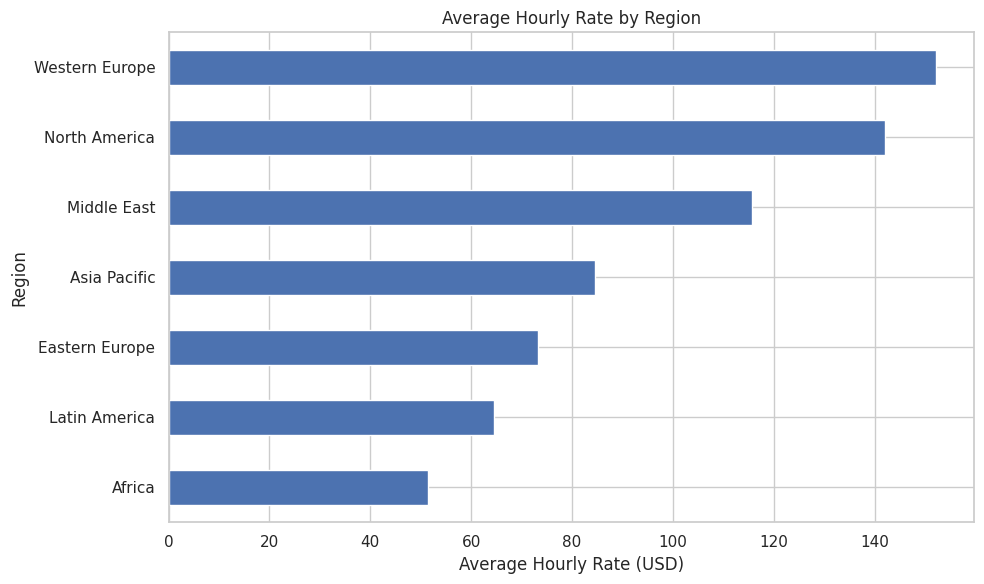

Average hourly rate by region:


,Average Hourly Rate (USD)
region,
Africa,51.41
Latin America,64.55
Eastern Europe,73.33
Asia Pacific,84.61
Middle East,115.59
North America,142.14
Western Europe,152.08


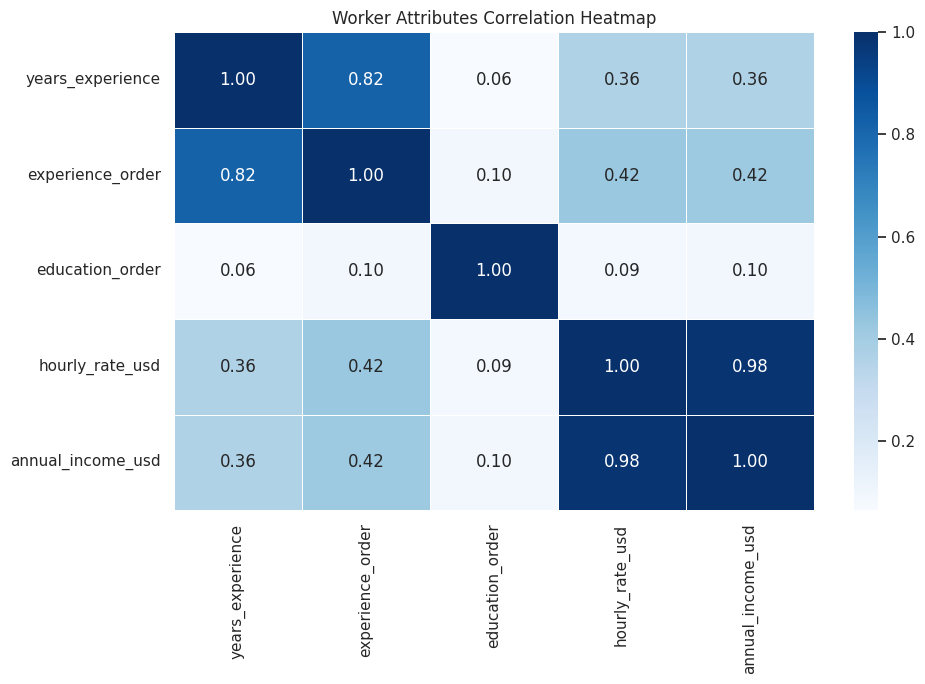

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns




fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=workers,
    x="hourly_rate_usd",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Hourly Rates")
axes[0].set_xlabel("Hourly Rate (USD)")
axes[0].set_ylabel("Number of Workers")




order = (
    workers.groupby("category")["hourly_rate_usd"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=workers,
    y="category",
    x="hourly_rate_usd",
    order=order,
    ax=axes[1]
)

axes[1].set_title("Hourly Rates by Category")
axes[1].set_xlabel("Hourly Rate (USD)")
axes[1].set_ylabel("Gig Category")

plt.tight_layout()
plt.show()




region_avg = (
    workers.groupby("region")["hourly_rate_usd"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))

region_avg.plot(
    kind="barh",
    title="Average Hourly Rate by Region"
)

plt.xlabel("Average Hourly Rate (USD)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

print("Average hourly rate by region:")
display(region_avg.round(2).to_frame("Average Hourly Rate (USD)"))




num = workers[[
    "years_experience",
    "experience_order",
    "education_order",
    "hourly_rate_usd",
    "annual_income_usd"
]].copy()


num = num.apply(pd.to_numeric, errors="coerce")


correlation = num.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Worker Attributes Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:
def group_test(df, group, value="earnings_usd"):
    groups = [g[value].values for _, g in df.groupby(group)]
    f_stat, p_anova = stats.f_oneway(*groups)
    h_stat, p_kruskal = stats.kruskal(*groups)
    grand_mean = df[value].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    ss_total = ((df[value] - grand_mean) ** 2).sum()
    return {"factor": group, "anova_p": p_anova, "kruskal_p": p_kruskal,
            "eta_squared": ss_between / ss_total}

factors = ["platform", "job_category", "experience_level", "project_type", "client_region"]
tests = pd.DataFrame([group_test(tx, f) for f in factors])
alpha = 0.05 / len(factors)
tests["significant"] = (tests["anova_p"] < alpha) & (tests["kruskal_p"] < alpha)
tests.round(4)

,factor,anova_p,kruskal_p,eta_squared,significant
0,platform,0.9669,0.9652,0.0003,False
1,job_category,0.5276,0.5331,0.0031,False
2,experience_level,0.0271,0.0264,0.0037,False
3,project_type,0.8170,0.8173,0.0000,False
4,client_region,0.4210,0.4181,0.0031,False


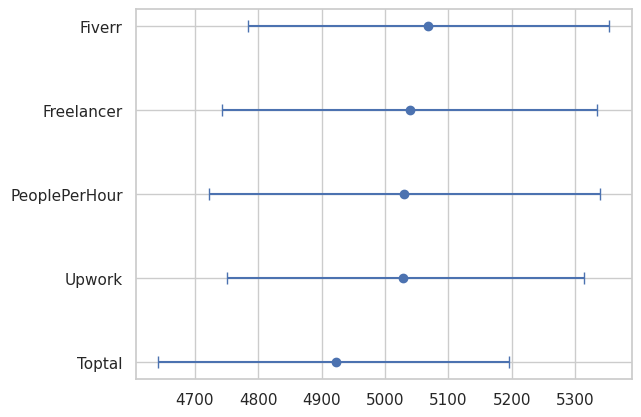

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)

def boot_ci(x, n_boot=5000):
    x = np.asarray(x)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

rows = []
for platform, g in tx.groupby("platform"):
    lo, hi = boot_ci(g["earnings_usd"])
    rows.append({"platform": platform, "n": len(g), "mean": g["earnings_usd"].mean(), "ci_low": lo, "ci_high": hi})
platform_ci = pd.DataFrame(rows).sort_values("mean", ascending=False)
platform_ci.round(0)

plt.errorbar(platform_ci["mean"], platform_ci["platform"],
             xerr=[platform_ci["mean"] - platform_ci["ci_low"],
                   platform_ci["ci_high"] - platform_ci["mean"]],
             fmt="o", capsize=4)
plt.gca().invert_yaxis(); plt.show()

In [ ]:
scenarios = {}
for fee in [5, 10, 15, 20]:
    net = tx["earnings_usd"] * (1 - fee / 100) - tx["marketing_spend_usd"]
    scenarios[f"{fee}% for all"] = net.groupby(tx["platform"]).mean()
scenarios["assumed fees"] = tx.groupby("platform")["est_net_earnings_usd"].mean()
fee_sensitivity = pd.DataFrame(scenarios).round(0)
fee_sensitivity

,5% for all,10% for all,15% for all,20% for all,assumed fees
platform,,,,,
Fiverr,4579.0,4326.0,4072.0,3819.0,3819.0
Freelancer,4533.0,4281.0,4029.0,3777.0,4281.0
PeoplePerHour,4533.0,4282.0,4030.0,3779.0,4282.0
Toptal,4416.0,4170.0,3924.0,3677.0,4170.0
Upwork,4531.0,4280.0,4029.0,3777.0,4280.0


In [ ]:
features_num = ["years_experience"]
features_cat = ["category", "region", "education", "primary_platform"]
X = workers[features_num + features_cat]
y = workers["hourly_rate_usd"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

prep = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), features_cat)],
    remainder="passthrough")

models = {
    "Baseline (mean)":   DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE),
}
results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({"model": name, "cv_r2": cv_r2.mean(),
                    "test_r2": r2_score(y_test, pred),
                    "test_mae_usd": mean_absolute_error(y_test, pred)})
    fitted[name] = pipe
metrics = pd.DataFrame(results).round(3)
metrics

,model,cv_r2,test_r2,test_mae_usd
0,Baseline (mean),-0.011,-0.013,41.429
1,Linear regression,0.682,0.673,21.806
2,Random forest,0.658,0.663,19.645


In [ ]:
rf = fitted["Random forest"]
perm = permutation_importance(rf, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="r2")
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
importance.round(3)

,0
region,0.976
years_experience,0.457
category,0.051
primary_platform,0.002
education,-0.000


In [ ]:
def predict_rate(years_experience, category, region, education, primary_platform):
    row = pd.DataFrame([{"years_experience": years_experience, "category": category,
                         "region": region, "education": education,
                         "primary_platform": primary_platform}])
    return float(fitted["Linear regression"].predict(row)[0])

predict_rate(3, "Data Engineering", "Asia Pacific", "Bachelor", "Upwork")

72.38030212088455

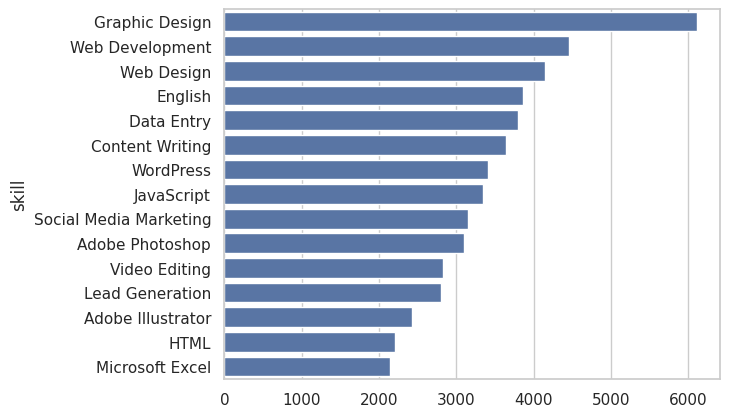

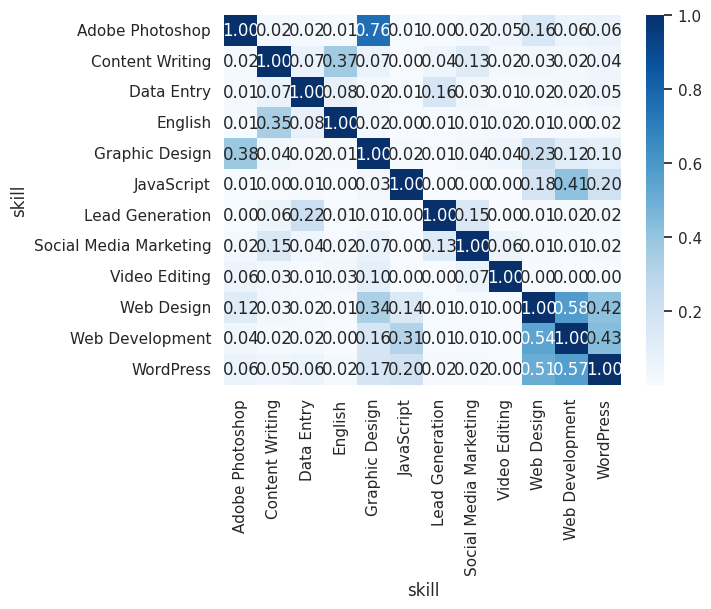

In [ ]:
top_skills = g_skills["skill"].value_counts().head(15)
sns.barplot(x=top_skills.values, y=top_skills.index); plt.show()

top12 = g_skills["skill"].value_counts().head(12).index
sub = g_skills[g_skills["skill"].isin(top12)]
m = pd.crosstab(sub["job_id"], sub["skill"]).clip(upper=1)
co = m.T.dot(m)
cond = co.div(np.diag(co), axis=0)
sns.heatmap(cond, annot=True, fmt=".2f", cmap="Blues"); plt.show()

In [ ]:
gig = workers.groupby("experience_level")["hourly_rate_usd"].mean()
sal = (tt[tt["job_level"].isin(["Entry", "Mid", "Senior"])]
       .assign(level=lambda d: d["job_level"].replace({"Entry": "Junior"}))
       .groupby("level")["effective_hourly_pay_usd"].mean())
bench = pd.DataFrame({"gig_rate": gig, "salaried_rate": sal}).loc[["Junior", "Mid", "Senior"]]
bench["gig_premium_pct"] = 100 * (bench["gig_rate"] / bench["salaried_rate"] - 1)
bench.round(1)

,gig_rate,salaried_rate,gig_premium_pct
Junior,NaN,59.1,NaN
Mid,NaN,60.0,NaN
Senior,NaN,58.7,NaN
